<a href="https://colab.research.google.com/github/lia-cloud/brain-project/blob/main/EEG_PhysioNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install mne scikit-learn matplotlib

In [2]:
import numpy as np
import mne
from mne.datasets import eegbci
from mne.io import concatenate_raws, read_raw_edf

mne.set_log_level('WARNING')

subjects = list(range(1, 11))
runs = [4, 8, 12]

X_all = []
y_all = []
groups = []

for s in subjects:
    files = eegbci.load_data(s, runs)
    raw = concatenate_raws([read_raw_edf(f, preload=True) for f in files])
    eegbci.standardize(raw)
    raw.set_montage('standard_1005')
    raw.filter(8., 30., fir_design='firwin')

    events, _ = mne.events_from_annotations(raw, event_id=dict(T1=2, T2=3))
    epochs = mne.Epochs(raw, events, dict(left=2, right=3),
                        tmin=0.5, tmax=3.5, baseline=None, preload=True)

    X_all.append(epochs.get_data())
    y_all.append(epochs.events[:, 2])
    groups += [s] * len(epochs)

X = np.concatenate(X_all)
y = np.concatenate(y_all)
groups = np.array(groups)
print(X.shape, y.shape)

Do you want to set the path:
    /root/mne_data
as the default EEGBCI dataset path in the mne-python config [y]/n? y


/tmp/ipykernel_1616/917060680.py:19: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')
Failed to download 'S002R04.edf'. Will attempt the download again 2 more times.
/tmp/ipykernel_1616/917060680.py:19: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')
/tmp/ipykernel_1616/917060680.py:19: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')
/tmp/ipykernel_1616/917060680.py:19: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')
Failed to download 'S005R04.edf'. Will attempt the download again 2 more times.
/tmp/ipykernel_1616/917060680.py:19: FutureWarning: Montage name 'standard_1

(450, 64, 481) (450,)


/tmp/ipykernel_1616/917060680.py:19: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage('standard_1005')


In [3]:
from mne.decoding import CSP
from sklearn.pipeline import make_pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import GroupKFold, cross_val_score

model = make_pipeline(CSP(n_components=4), LinearDiscriminantAnalysis())

scores = cross_val_score(model, X, y, groups=groups,
                         cv=GroupKFold(n_splits=5))
print('Accuracy on new subjects:', scores.mean())

Accuracy on new subjects: 0.5222222222222221


Subject 1 accuracy: 0.49
Subject 2 accuracy: 0.51
Subject 3 accuracy: 0.4
Subject 4 accuracy: 0.56
Subject 5 accuracy: 0.53
Subject 6 accuracy: 0.53
Subject 7 accuracy: 0.62
Subject 8 accuracy: 0.6
Subject 9 accuracy: 0.53
Subject 10 accuracy: 0.47
Mean accuracy: 0.52


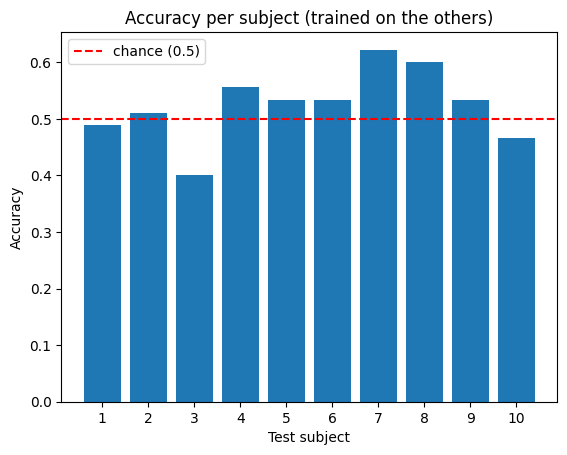

In [4]:
import matplotlib.pyplot as plt
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import accuracy_score

logo = LeaveOneGroupOut()
y_pred = cross_val_predict(model, X, y, groups=groups, cv=logo)

subject_ids = sorted(set(groups))
subject_scores = []
for s in subject_ids:
    mask = groups == s
    subject_scores.append(accuracy_score(y[mask], y_pred[mask]))

for s, a in zip(subject_ids, subject_scores):
    print('Subject', s, 'accuracy:', round(a, 2))

print('Mean accuracy:', round(np.mean(subject_scores), 2))

plt.bar([str(s) for s in subject_ids], subject_scores)
plt.axhline(0.5, color='red', linestyle='--', label='chance (0.5)')
plt.xlabel('Test subject')
plt.ylabel('Accuracy')
plt.title('Accuracy per subject (trained on the others)')
plt.legend()
plt.show()